# Examen Práctico — Primer Parcial
## Tópicos de Big Data

**Instrucciones generales**

- Este notebook es tu entregable. Complétalo en orden, sin borrar los enunciados.
- Al final debes subir este archivo (`.ipynb`) al repositorio de GitHub del curso, en la carpeta correspondiente a tu nombre/usuario.
- Se evaluará tanto el código (que corra sin errores, de arriba hacia abajo) como tus interpretaciones escritas en las celdas de texto marcadas como *"Interpretación"*.
- Cada quien trabaja con **un dataset distinto**, asignado por la profesora. No copies celdas de un compañero con un dataset diferente: aunque las preguntas se parecen, los datos y las columnas no son las mismas.


## 0. Datos del alumno

Completa la siguiente celda con tus datos y el nombre del dataset que te fue asignado.

In [1]:
# --- COMPLETA CON TUS DATOS ---
NOMBRE = "Victor Sebastien Davalos Leon"            # Tu nombre completo
MATRICULA = "81372"         # Tu matrícula o número de cuenta
DATASET_ASIGNADO = "desnutricion"  # Debe ser uno de: "alcohol", "migracion", "desnutricion", "pib", "homicidios"

print(f"Alumno: {NOMBRE}")
print(f"Matrícula: {MATRICULA}")
print(f"Dataset asignado: {DATASET_ASIGNADO}")


Alumno: Victor Sebastien Davalos Leon
Matrícula: 81372
Dataset asignado: desnutricion


## 1. Configuración del entorno virtual (Visual Studio Code)

Antes de instalar librerías directamente en tu sistema, es una buena práctica crear un
**entorno virtual** exclusivo para este examen. Esto evita conflictos de versiones con
otros proyectos y hace que tu entorno de trabajo sea reproducible.

**Requisitos previos en VS Code:** ten instaladas las extensiones oficiales **"Python"**
y **"Jupyter"** (ambas de Microsoft), disponibles en la pestaña de Extensiones (ícono de
cuadritos en la barra lateral izquierda, o `Ctrl+Shift+X` / `Cmd+Shift+X`).

Abre una terminal **dentro de VS Code** (menú **Terminal → New Terminal**, o
`` Ctrl+ñ ``/`` Ctrl+` ``) y verifica que estés ubicado en la carpeta de tu repositorio
del curso (donde vas a guardar este notebook).

### Windows (PowerShell, terminal integrada de VS Code)

```powershell
# 1. Crear el entorno virtual (se creará una carpeta llamada ".venv")
python -m venv .venv

# 2. Activar el entorno virtual
.venv\Scripts\Activate.ps1

# Si PowerShell bloquea la ejecución de scripts, ejecuta una sola vez:
#   Set-ExecutionPolicy -Scope CurrentUser RemoteSigned
# y vuelve a intentar activar el entorno.

# 3. Instalar las librerías necesarias
pip install pandas numpy ipykernel matplotlib requests
```

### macOS / Linux (terminal integrada de VS Code, bash o zsh)

```bash
# 1. Crear el entorno virtual (se creará una carpeta llamada ".venv")
python3 -m venv .venv

# 2. Activar el entorno virtual
source .venv/bin/activate

# 3. Instalar las librerías necesarias
pip install pandas numpy ipykernel matplotlib requests
```

> **Nota:** usamos el nombre `.venv` (con punto) porque VS Code lo detecta automáticamente
> dentro de la carpeta del proyecto. Si usas Anaconda/Miniconda en lugar de `venv`, el
> equivalente es:
> ```bash
> conda create -n examen-bigdata python=3.11 pandas numpy ipykernel matplotlib requests -y
> conda activate examen-bigdata
> ```

### Seleccionar el entorno virtual como kernel en VS Code

A diferencia de Jupyter Notebook/Lab, en VS Code **no necesitas registrar el entorno
manualmente con `ipykernel install`**: basta con tener el paquete `ipykernel` instalado
en el entorno (ya quedó instalado en el paso anterior) y seleccionar ese entorno
directamente como kernel del notebook.

1. Abre este archivo `.ipynb` en VS Code.
2. En la esquina superior derecha del notebook, haz clic en el selector de kernel
   (dice algo como **"Select Kernel"** la primera vez).
3. Elige **"Python Environments..."** y de la lista selecciona el entorno `.venv`
   que acabas de crear (debe aparecer como algo como `.venv (Python 3.x.x)` con la
   ruta de tu proyecto).
4. Si no aparece en la lista, haz clic en **"Select Another Kernel" → "Python
   Environments..."** y usa **"Enter interpreter path..."** para localizar manualmente
   el ejecutable dentro de `.venv/bin/python` (macOS/Linux) o `.venv\Scripts\python.exe`
   (Windows).
5. Verifica que quedó bien seleccionado ejecutando la celda de abajo: debe mostrar una
   ruta que contenga la carpeta `.venv` (o el nombre de tu entorno de conda), y no la
   instalación global de Python.

In [2]:
import sys
print(sys.executable)
# Debe mostrar una ruta dentro de tu carpeta "venv" (o de tu entorno "examen-bigdata" si usas conda).
# Si muestra la ruta de tu instalacion global de Python, regresa al paso anterior
# y selecciona el kernel correcto antes de continuar.


c:\Users\vdjun\anaconda3\python.exe


## 2. Configuración y carga de datos

La siguiente celda **no se modifica**. Contiene la configuración de los 5 datasets
posibles del examen. A partir de tu variable `DATASET_ASIGNADO` de la celda anterior,
el notebook cargará automáticamente el dataset y los metadatos que te corresponden.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests

# --- NO MODIFICAR: configuración de los 5 datasets del examen ---
DATASETS = {
    "alcohol": {
        "csv": "https://ourworldindata.org/grapher/share-of-adults-who-drank-alcohol-in-last-year.csv?v=1&csvType=full&useColumnShortNames=true",
        "meta": "https://ourworldindata.org/grapher/share-of-adults-who-drank-alcohol-in-last-year.metadata.json?v=1&csvType=full&useColumnShortNames=true",
        "valor_col": "alcohol__consumers_past_12_months__pct__age_standardized__sex_both_sexes",
        "filtro_paises": "code",       # columna a usar para filtrar países reales vs. agregados
        "descripcion": "Porcentaje de adultos (15+) que bebieron alcohol en el ultimo anio",
        "unidad": "%",
    },
    "migracion": {
        "csv": "https://ourworldindata.org/grapher/migrant-populations.csv?v=1&csvType=full&useColumnShortNames=true&metric=immigrants&unit=number",
        "meta": "https://ourworldindata.org/grapher/migrant-populations.metadata.json?v=1&csvType=full&useColumnShortNames=true&metric=immigrants&unit=number",
        "valor_col": "immigrants_all",
        "filtro_paises": "owid_region",
        "descripcion": "Numero total de inmigrantes internacionales residiendo en el pais",
        "unidad": "personas",
    },
    "desnutricion": {
        "csv": "https://ourworldindata.org/grapher/number-undernourished.csv?v=1&csvType=full&useColumnShortNames=true",
        "meta": "https://ourworldindata.org/grapher/number-undernourished.metadata.json?v=1&csvType=full&useColumnShortNames=true",
        "valor_col": "_2_1_1_number_of_undernourished_people__000000000024001__value__006132__millions",
        "filtro_paises": "code",
        "descripcion": "Numero de personas subalimentadas (desnutricion)",
        "unidad": "personas",
    },
    "pib": {
        "csv": "https://ourworldindata.org/grapher/gdp-per-capita-worldbank-constant-usd.csv?v=1&csvType=full&useColumnShortNames=true",
        "meta": "https://ourworldindata.org/grapher/gdp-per-capita-worldbank-constant-usd.metadata.json?v=1&csvType=full&useColumnShortNames=true",
        "valor_col": "ny_gdp_pcap_kd",
        "filtro_paises": "code",
        "descripcion": "PIB per capita (dolares constantes de 2015)",
        "unidad": "USD",
    },
    "homicidios": {
        "csv": "https://ourworldindata.org/grapher/homicides-unodc.csv?v=1&csvType=full&useColumnShortNames=true",
        "meta": "https://ourworldindata.org/grapher/homicides-unodc.metadata.json?v=1&csvType=full&useColumnShortNames=true",
        "valor_col": "value__category_total__sex_total__age_total__unit_of_measurement_counts",
        "filtro_paises": "owid_region",
        "descripcion": "Numero de homicidios intencionales por anio",
        "unidad": "homicidios",
    },
}

assert DATASET_ASIGNADO in DATASETS, (
    "DATASET_ASIGNADO debe ser uno de: " + ", ".join(DATASETS.keys())
)

config = DATASETS[DATASET_ASIGNADO]
print(f"Cargando dataset: {DATASET_ASIGNADO}")
print(f"Descripcion: {config['descripcion']} ({config['unidad']})")


Cargando dataset: desnutricion
Descripcion: Numero de personas subalimentadas (desnutricion) (personas)


In [4]:
# Carga de datos y metadatos desde Our World in Data
df = pd.read_csv(
    config["csv"],
    storage_options={'User-Agent': 'Our World In Data data fetch/1.0'}
)
metadata = requests.get(config["meta"]).json()

# Renombramos la columna de valor a "valor" para trabajar mas comodo durante todo el notebook
df = df.rename(columns={config["valor_col"]: "valor"})


In [5]:
df.head(25)

,entity,code,year,valor
0,Afghanistan,AFG,2001,9400000.0
1,Afghanistan,AFG,2002,9300000.0
2,Afghanistan,AFG,2003,8700000.0
3,Afghanistan,AFG,2004,8200000.0
4,Afghanistan,AFG,2005,7500000.0
5,Afghanistan,AFG,2006,6700000.0
6,Afghanistan,AFG,2007,5900000.0
7,Afghanistan,AFG,2008,5200000.0
8,Afghanistan,AFG,2009,4800000.0
9,Afghanistan,AFG,2010,5000000.0


## 3. Exploración inicial

Antes de responder las preguntas de análisis, explora el dataset: tipos de datos,
dimensiones, valores nulos y estadísticas descriptivas básicas.

In [6]:
# Forma del dataset (filas, columnas)
df.shape


(3544, 4)

In [7]:
# Tipos de datos e informacion general
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3544 entries, 0 to 3543
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   entity  3544 non-null   object 
 1   code    2758 non-null   object 
 2   year    3544 non-null   int64  
 3   valor   3544 non-null   float64
dtypes: float64(1), int64(1), object(2)
memory usage: 110.9+ KB


In [8]:
# Estadisticas descriptivas de la columna 'valor'
df['valor'].describe()


count    3.544000e+03
mean     3.061574e+07
std      8.749230e+07
min      1.000000e+05
25%      3.000000e+05
50%      2.100000e+06
75%      9.925000e+06
max      8.252000e+08
Name: valor, dtype: float64

In [9]:
# Conteo de valores nulos por columna
df.isnull().sum()


entity      0
code      786
year        0
valor       0
dtype: int64

**Interpretación (2-3 líneas):** ¿qué observas sobre los valores nulos, el rango de
años y el tipo de variable con la que vas a trabajar?

*(Escribe aquí tu respuesta)*

## 4. Preguntas de análisis

A continuación responde las 10 preguntas. 

Cada una tiene una celda de código para su solución y, cuando aplica, 
una celda de texto para tu interpretación. Recuerda que tu
dataset (`DATASET_ASIGNADO`) puede o no tener la columna `owid_region`; revisa el
diccionario `DATASETS` de la celda de configuración para saber qué columna (`code` u
`owid_region`) te toca usar para distinguir países reales de agregados (continentes,
"World", grupos de ingreso, etc.).

### Pregunta 1 — Filtrado de países reales y ranking

Filtra el DataFrame para quedarte solo con países reales (usa la columna indicada en `config['filtro_paises']` de tu dataset). Guarda el resultado en una nueva variable `df_paises`. ¿Cuántos países distintos hay? Muestra los 10 países con mayor valor y los 10 con menor valor.

In [10]:
# Pregunta 1
# Tu codigo aqui
df_paises = df[
    df[config["filtro_paises"]].notnull() &
    ~df[config["filtro_paises"]].str.startswith("OWID_", na=False)
]
n_paises = df_paises['entity'].nunique()
print(f"Numero de paises distintos: {n_paises}")
top_10 = df_paises.sort_values('valor', ascending=False).head(10)
print(top_10)
bottom_10 = df_paises.sort_values('valor', ascending=True).head(10)
print(bottom_10)

Numero de paises distintos: 139
     entity code  year        valor
1341  India  IND  2004  247000000.0
1342  India  IND  2005  243900000.0
1340  India  IND  2003  236800000.0
1343  India  IND  2006  222200000.0
1339  India  IND  2002  216300000.0
1358  India  IND  2021  201900000.0
1344  India  IND  2007  197200000.0
1338  India  IND  2001  194900000.0
1359  India  IND  2022  192000000.0
1357  India  IND  2020  188400000.0
       entity code  year     valor
3339  Vanuatu  VUT  2006  100000.0
3338  Vanuatu  VUT  2005  100000.0
3337  Vanuatu  VUT  2004  100000.0
3336  Vanuatu  VUT  2003  100000.0
3335  Vanuatu  VUT  2002  100000.0
64    Albania  ALB  2017  100000.0
63    Albania  ALB  2016  100000.0
62    Albania  ALB  2015  100000.0
61    Albania  ALB  2014  100000.0
60    Albania  ALB  2013  100000.0


**Interpretación:**

*Quedan 139 paises reales, en el top 10 con mas valor, todas las filas estan de la india en varios anios lo cual es esperable ya que la india tiene la mayor poblacion del mundo asi que su valor absoluto si es muy grande por eso, en el bottom 10 salen vanuatu y albania, ambos estan con el valor minimo posible*

### Pregunta 2 — Filtro por país y rango de años

Elige dos paises (Mexico y algún otro de tu interés) y filtra `df_paises` para mostrar únicamente su información dentro del rango de años disponible para ambos.

In [11]:
# Pregunta 2
# Tu codigo aqui
paises_interes = ["Mexico", "Brazil"]
df_dos = df_paises[df_paises["entity"].isin(paises_interes)]
anio_min = df_dos.groupby("entity")["year"].min().max()
anio_max = df_dos.groupby("entity")["year"].max().min()
df_dos_filtrado = df_dos[(df_dos["year"] >= anio_min) & (df_dos["year"] <= anio_max)]
df_dos_filtrado

,entity,code,year,valor
338,Brazil,BRA,2001,18400000.0
339,Brazil,BRA,2002,16200000.0
340,Brazil,BRA,2003,13800000.0
341,Brazil,BRA,2004,11500000.0
342,Brazil,BRA,2005,10500000.0
343,Brazil,BRA,2006,9400000.0
344,Brazil,BRA,2007,8500000.0
345,Brazil,BRA,2008,7600000.0
346,Brazil,BRA,2009,6700000.0
347,Brazil,BRA,2010,5800000.0


### Pregunta 3 — Comparación entre países

Elige 5 países de tu interés (de distintos continentes) y compara el valor de tu indicador en el año más reciente disponible. ¿Cuál tiene el valor más alto y cuál el más bajo? Calcula la diferencia entre ambos.

In [12]:
# Pregunta 3
# Tu codigo aqui
paises_5 = ["Mexico", "Nigeria", "India", "France", "Australia"]
df_5 = df_paises[df_paises["entity"].isin(paises_5)]
anio_reciente = df_5.groupby("entity")["year"].max().min()
df_5_reciente = df_5[df_5["year"] == anio_reciente]
valor_max = df_5_reciente["valor"].max()
valor_min = df_5_reciente["valor"].min()
pais_max = df_5_reciente.loc[df_5_reciente["valor"].idxmax(), "entity"]
pais_min = df_5_reciente.loc[df_5_reciente["valor"].idxmin(), "entity"]
diferencia = valor_max - valor_min
print(df_5_reciente)
print(anio_reciente, pais_max, valor_max, pais_min, valor_min, diferencia)

       entity code  year        valor
1360    India  IND  2023  172100000.0
1986   Mexico  MEX  2023    3500000.0
2260  Nigeria  NGA  2023   45400000.0
2023 India 172100000.0 Mexico 3500000.0 168600000.0


**Interpretación:**

*de la prgunta 2 brasil y mexico tienen datos en comun de 2001 a 2022, brasil se vio una caida en el numero de personas subalimentadas pero se recupera un pco entre 2020 y 2022, mexico se mantiene mas estable en si sin cambios tan fuertes*

### Pregunta 4 — Comparación entre grupos

Define dos grupos de países, el primero "latinoamerica" con Mexico, Colombia y Argentina, y el segundo "Asia" con China, Japon y Vietnam ( si algun pais no tiene informacion disponible, sustitúyelo por algún otro) y calcula el promedio de tu indicador en el año más reciente disponible.

In [13]:
# Pregunta 4
# Tu codigo aqui
latam = ["Mexico", "Colombia", "Argentina"]
asia = ["China", "Japan", "Vietnam"]
df_latam = df_paises[df_paises["entity"].isin(latam)]
df_asia = df_paises[df_paises["entity"].isin(asia)]
anio_latam = df_latam.groupby("entity")["year"].max().min()
anio_asia = df_asia.groupby("entity")["year"].max().min()
promedio_latam = df_latam[df_latam["year"] == anio_latam]["valor"].mean()
promedio_asia = df_asia[df_asia["year"] == anio_asia]["valor"].mean()
print(anio_latam, promedio_latam)
print(anio_asia, promedio_asia)

2023 2333333.3333333335
2009 24100000.0


**Interpretación:**

*el anio mas reciente para ambos grupos es diferente el de latam es hasta 2023 con un promedio de 2.33 millones de personas subalimentadas, asia solo llega hasta 2009 con un promedio de 24.1 millones, esta diferencia es a lo mejor uno de los paises elegidos no tiene datos en anios recientes, en si el grupo asiatico da un valor absoluto mucho mayor, que tambien creo que esta relacionado con la poblacion de china*

### Pregunta 5 — Tendencia temporal de un país

Para un país de tu elección, analiza cómo cambió tu indicador a lo largo del tiempo disponible en el dataset. ¿En qué año tuvo su valor máximo y en cuál el mínimo? ¿La tendencia general es creciente, decreciente o fluctuante?

In [14]:
# Pregunta 5
# Tu codigo aqui
pais_tendencia = "Mexico"
df_pais = df_paises[df_paises["entity"] == pais_tendencia].sort_values("year")
anio_max_val = df_pais.loc[df_pais["valor"].idxmax(), "year"]
anio_min_val = df_pais.loc[df_pais["valor"].idxmin(), "year"]
valor_max_val = df_pais["valor"].max()
valor_min_val = df_pais["valor"].min()
print(df_pais)
print(anio_max_val, valor_max_val, anio_min_val, valor_min_val)

      entity code  year      valor
1964  Mexico  MEX  2001  2800000.0
1965  Mexico  MEX  2002  3300000.0
1966  Mexico  MEX  2003  3900000.0
1967  Mexico  MEX  2004  4300000.0
1968  Mexico  MEX  2005  4200000.0
1969  Mexico  MEX  2006  4000000.0
1970  Mexico  MEX  2007  4000000.0
1971  Mexico  MEX  2008  4400000.0
1972  Mexico  MEX  2009  4600000.0
1973  Mexico  MEX  2010  4600000.0
1974  Mexico  MEX  2011  4400000.0
1975  Mexico  MEX  2012  4500000.0
1976  Mexico  MEX  2013  4400000.0
1977  Mexico  MEX  2014  4500000.0
1978  Mexico  MEX  2015  4400000.0
1979  Mexico  MEX  2016  4500000.0
1980  Mexico  MEX  2017  4600000.0
1981  Mexico  MEX  2018  4500000.0
1982  Mexico  MEX  2019  4300000.0
1983  Mexico  MEX  2020  3900000.0
1984  Mexico  MEX  2021  3800000.0
1985  Mexico  MEX  2022  3600000.0
1986  Mexico  MEX  2023  3500000.0
2009 4600000.0 2001 2800000.0


**Interpretación:**

*el valor minimo en mexico se registro en 2001 y el maximo en 2009, en si varea hay un crecimietno de 2001 a 2009 luego se mantiene estable entre 2010 a 2018 y luego se muestra como va bajando de 2019 a 2023*

### Pregunta 6 — Cambio porcentual

Para Mexico, calcula el cambio porcentual entre el primer y el último año con datos disponible. ¿presenta un incremento relativo o una caída? En tus palabras, ¿a qué crees que se debe el resultado? 

In [15]:
# Pregunta 6
# Tu codigo aqui
df_mexico = df_paises[df_paises["entity"] == "Mexico"].sort_values("year")
valor_inicial = df_mexico.iloc[0]["valor"]
valor_final = df_mexico.iloc[-1]["valor"]
anio_inicial = df_mexico.iloc[0]["year"]
anio_final = df_mexico.iloc[-1]["year"]
cambio_pct = (valor_final - valor_inicial) / valor_inicial * 100
print(anio_inicial, valor_inicial, anio_final, valor_final, cambio_pct)

2001 2800000.0 2023 3500000.0 25.0


**Interpretación:**

*de 2001 a 2023 las personas subalimentadas en mexico paso de 2.8 a 3.5 millones lo que es un incremento relativo del 25% y esto aunque hubo una caida en los ultimos anios, este aumento podria explicar por el crecimiento en la poblacion en el pais en esas dos decadas*

### Pregunta 7 — Estadísticas descriptivas con NumPy

Usando NumPy (no `.describe()` de pandas), calcula la media, la mediana y la desviación estándar de tu columna valor entre todos los países reales, para el año más reciente disponible. 
Recuerda filtrar los `NaN` antes de calcular.

In [16]:
# Pregunta 7
# Tu codigo aqui
anio_reciente_global = df_paises["year"].max()
valores_recientes = df_paises[df_paises["year"] == anio_reciente_global]["valor"].dropna().to_numpy()
media_np = np.mean(valores_recientes)
mediana_np = np.median(valores_recientes)
std_np = np.std(valores_recientes)
print(anio_reciente_global, media_np, mediana_np, std_np)

2023 5884761.904761905 1600000.0 18150375.994806126


**Interpretación:**

*en 2023 la media de personas es de 1.6 millones esto se ve como una distribucion media rara ya que la desviacion estandar es muy grande de 18.15 millones osea mas grande q la media, lo cual me dice que la dispersion y los valores atipicos influyen mucho*

### Pregunta 8 — Visualización de tendencia

Crea una gráfica de líneas con matplotlib que muestre la evolución de tu indicador a lo largo del tiempo para 3 países de tu elección, en una sola figura, con título, etiquetas de ejes y leyenda.

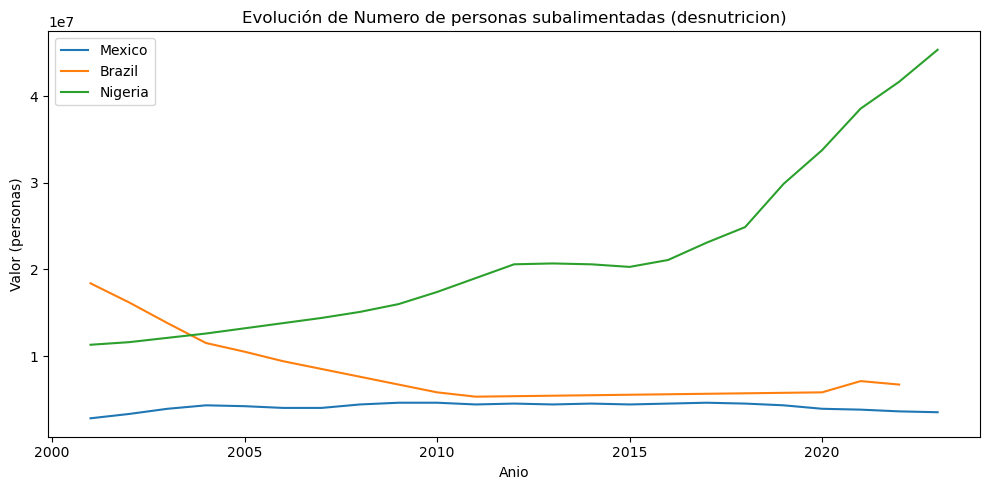

In [17]:
# Pregunta 8
# Tu codigo aqui
paises_grafica = ["Mexico", "Brazil", "Nigeria"]
plt.figure(figsize=(10, 5))
for pais in paises_grafica:
    df_p = df_paises[df_paises["entity"] == pais].sort_values("year")
    plt.plot(df_p["year"], df_p["valor"], label=pais)
plt.xlabel("Anio")
plt.ylabel(f"Valor ({config['unidad']})")
plt.title(f"Evolución de {config['descripcion']}")
plt.legend()
plt.tight_layout()
plt.show()

**Interpretación:**

*en la grafica las tres son muy diferentes, nigeria tiene el crecimietno sostenido y acelerado, brasil se ve que esta en el valor mas alto de los tres y cae hasta que se sostien y sube un poco, mexico se mantiene mas estable pero mas abajo*

### Pregunta 9 — Visualización integradora

Crea dos gráficas de barras (horizontales o verticales) con el Top 10 de países según tu indicador en la primera consulta el año de tu nacimiento, y en la segunda el año 2023, ordenados de mayor a menor.  Qué movimientos hubo en ambas gráficas?
Agrega título y etiquetas de ejes.

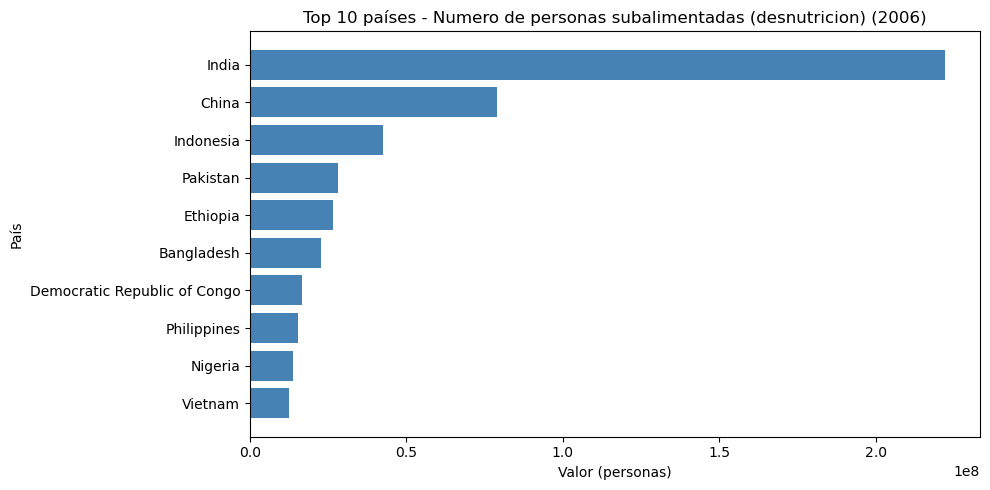

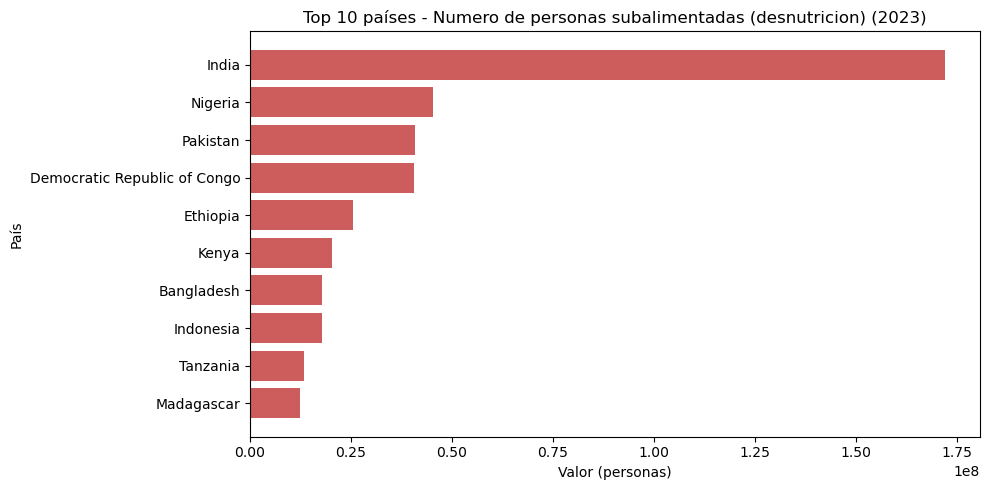

In [18]:
# Pregunta 9
# Tu codigo aqui
anio_nacimiento = 2006
anio_2023 = 2023
top_nacimiento = df_paises[df_paises["year"] == anio_nacimiento].sort_values("valor", ascending=False).head(10)
top_2023 = df_paises[df_paises["year"] == anio_2023].sort_values("valor", ascending=False).head(10)
plt.figure(figsize=(10, 5))
plt.barh(top_nacimiento["entity"], top_nacimiento["valor"], color="steelblue")
plt.xlabel(f"Valor ({config['unidad']})")
plt.ylabel("País")
plt.title(f"Top 10 países - {config['descripcion']} ({anio_nacimiento})")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()
plt.figure(figsize=(10, 5))
plt.barh(top_2023["entity"], top_2023["valor"], color="indianred")
plt.xlabel(f"Valor ({config['unidad']})")
plt.ylabel("País")
plt.title(f"Top 10 países - {config['descripcion']} ({anio_2023})")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


**Interpretación:**

*india esta en el primer lugar en los dos, lo unico es que su valor disminuyo, el cambio que se ve mas es el de china ya que en 2006 era segundo lugar pero desaparece del rop 10 del 2023, por otro lado nigeria sube muy fuerte hasta segundo lugar en 2023 y aparecen nuevos paises de africa, esto nos deja ver como varios paises de africa empeoran*

## 5. Conclusión general

En 5 - 10 líneas, resume qué aprendiste sobre el dataset que te tocó trabajar: ¿qué
patrones encontraste?, ¿qué limitaciones tiene la información (por ejemplo, valores
absolutos sin normalizar por población, datos faltantes, etc.)?, ¿qué harías distinto si
tuvieras más tiempo?

*al ver este dataset vi que los valores absolutos esta sesgado por el tamanio de la poblacion de cada pais, brasil y china mejoraron en las ultimas decadas mientras que paises de africa empeoraron mucho, mexico se ha mantenido muy estable con un leve aumento del 25%, y que el dataset tiene limitaciones como la falta de datos para paises como francia o australia, para poder comparar de forma mas justa entre paises de diferentes tamanios y ver mejor que naciones tienen realmente una sitacion muy grave*

## 6. Entrega

1. Verifica que el notebook corra completo de arriba hacia abajo sin errores (`Kernel > Restart & Run All`).
2. Guarda el archivo con el nombre: `apellido_nombre_examen_parcial1.ipynb`.
3. Súbelo al repositorio de GitHub del curso, en una carpeta para este examen.
4. Comparte el link de tu repo y envia una copia del notebook por teams.
